[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/bihjane/data-science-and-ai-k-12-teaching-tools/blob/main/intelligent-futures-free-courses/colab-notebooks/05_neural_network_handwritten_digits.ipynb)

# A neural network that reads handwritten digits
**Level:** intermediate · **Time:** 60 minutes · **Model:** neural network (multi-layer perceptron)

**Question:** Can a computer learn to read handwritten numbers 0 to 9 from examples?

Data: 1,797 images of handwritten digits (8 × 8 pixels), built into scikit-learn. An optional final step uses Keras and the larger MNIST dataset (70,000 images).

## How to use this notebook
1. Click **Open in Colab** above, or upload this file at [colab.research.google.com](https://colab.research.google.com) (File > Upload notebook).
2. Run each code cell in order with **Shift + Enter**.
3. Before running a cell, **predict** what it will show. After running it, check your prediction.
4. Try the **Your turn** tasks at the end of each step.

No installs or downloads are needed. Everything runs free in your browser.

## Step 1. Load and view the images

(1797, 8, 8)


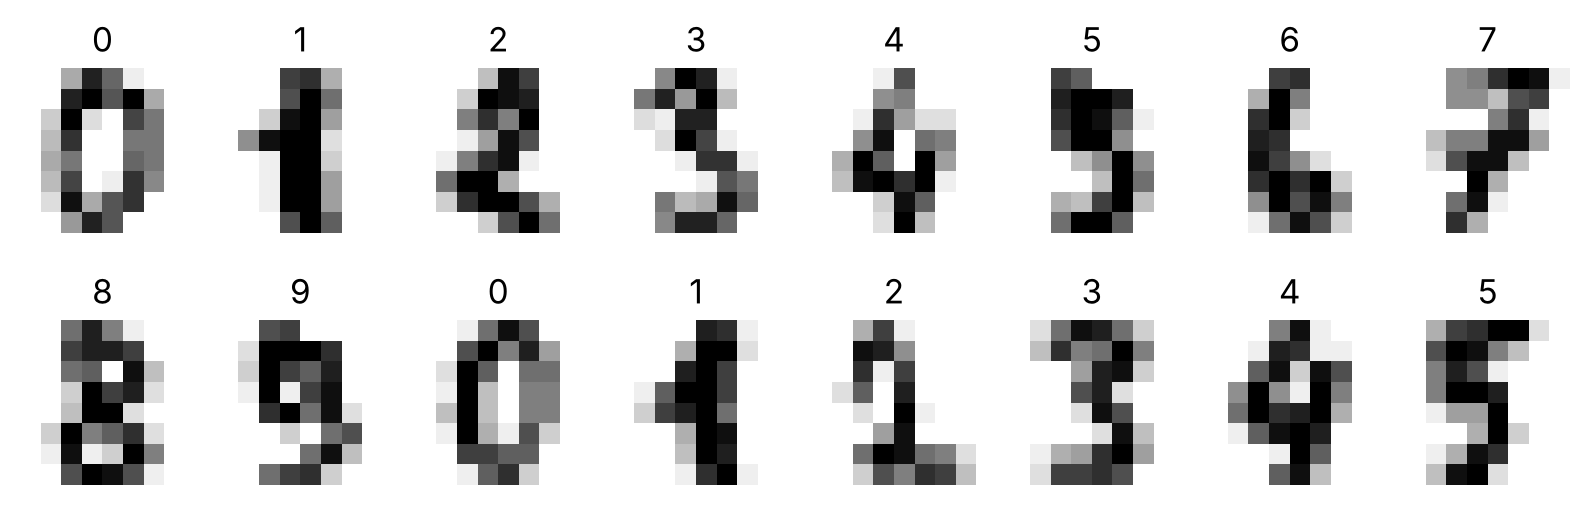

In [1]:
import numpy as np, matplotlib.pyplot as plt
from sklearn.datasets import load_digits

digits = load_digits()
print(digits.images.shape)        # 1797 images, each 8 x 8

fig, axes = plt.subplots(2, 8, figsize=(10,3))
for ax, img, label in zip(axes.ravel(), digits.images, digits.target):
    ax.imshow(img, cmap="gray_r"); ax.set_title(label); ax.axis("off")
plt.show()

## Step 2. Turn images into numbers
Each image becomes a row of 64 numbers (pixel darkness 0 to 16). We scale them to 0 to 1.

In [2]:
X = digits.data / 16.0
y = digits.target
print(X.shape, "->", X[0][:16], "...")

(1797, 64) -> [0.     0.     0.3125 0.8125 0.5625 0.0625 0.     0.     0.     0.
 0.8125 0.9375 0.625  0.9375 0.3125 0.    ] ...


## Step 3. Split

In [3]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print(len(X_train), "training images,", len(X_test), "test images")

1437 training images, 360 test images


## Step 4. Start simple: a baseline model

In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

base = LogisticRegression(max_iter=2000).fit(X_train, y_train)
print("Logistic regression accuracy:", round(accuracy_score(y_test, base.predict(X_test)), 3))

Logistic regression accuracy: 0.956


## Step 5. Train a neural network
Our network has 64 inputs, one hidden layer of 64 neurons, and 10 outputs (one per digit). Each neuron combines its inputs with **weights**. Training adjusts the weights step by step to reduce the error (gradient descent).

Neural network accuracy: 0.981


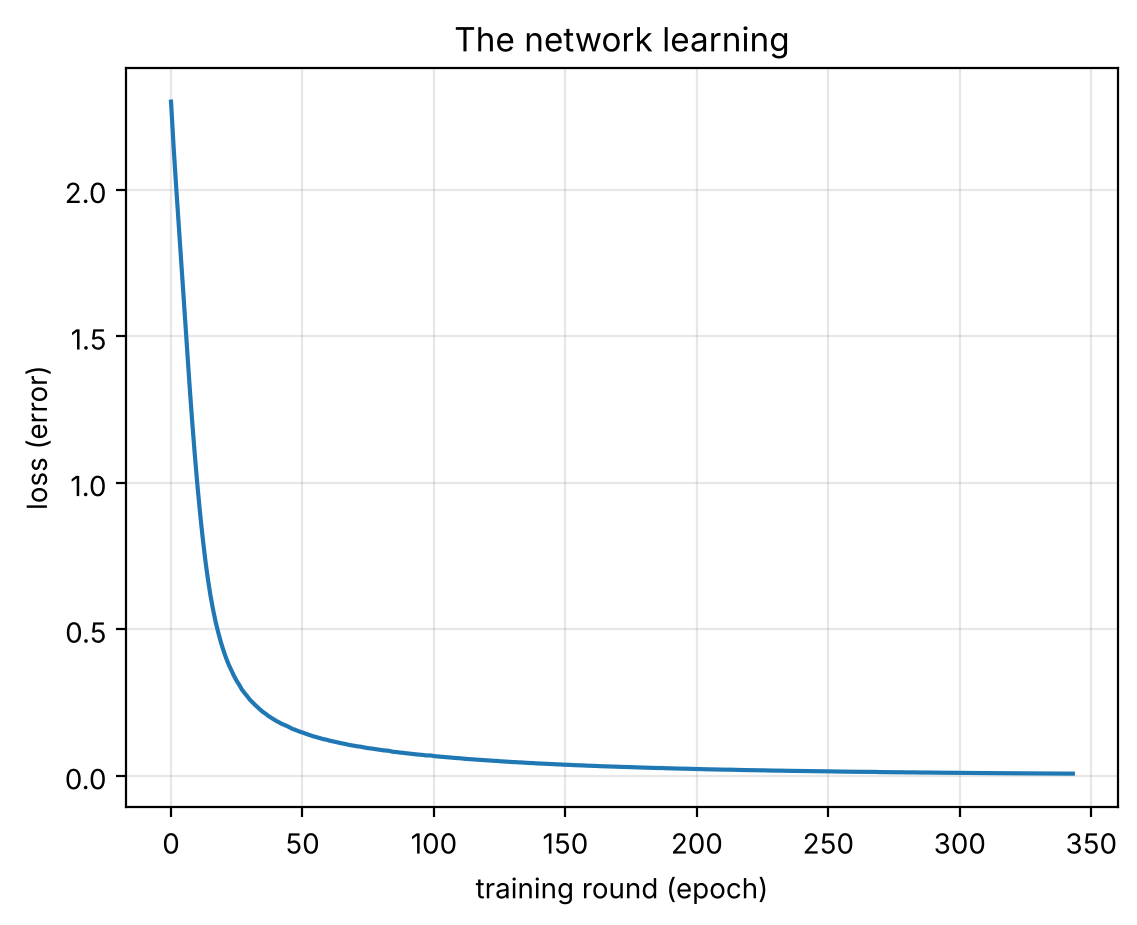

In [5]:
from sklearn.neural_network import MLPClassifier

net = MLPClassifier(hidden_layer_sizes=(64,), max_iter=1000, random_state=42)
net.fit(X_train, y_train)
print("Neural network accuracy:", round(accuracy_score(y_test, net.predict(X_test)), 3))

plt.plot(net.loss_curve_)
plt.xlabel("training round (epoch)"); plt.ylabel("loss (error)"); plt.title("The network learning")
plt.grid(alpha=0.3); plt.show()

The falling **loss curve** shows the network getting better with each round.

## Step 6. Where does it make mistakes?

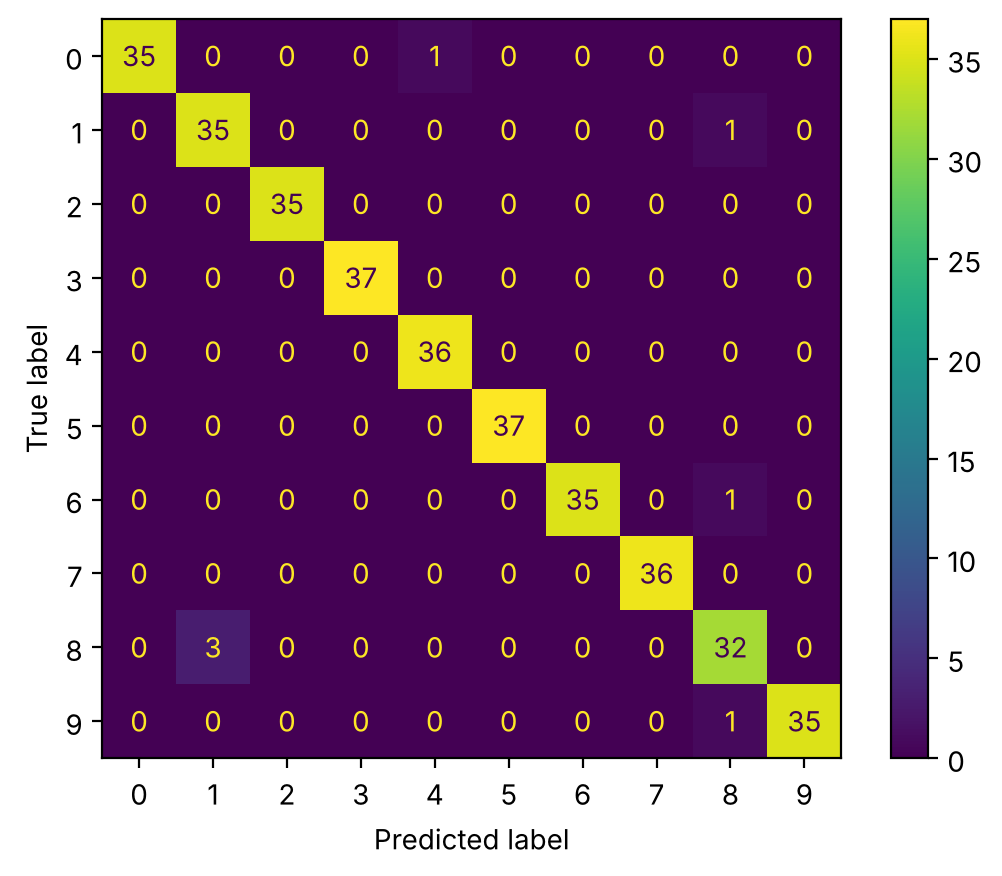

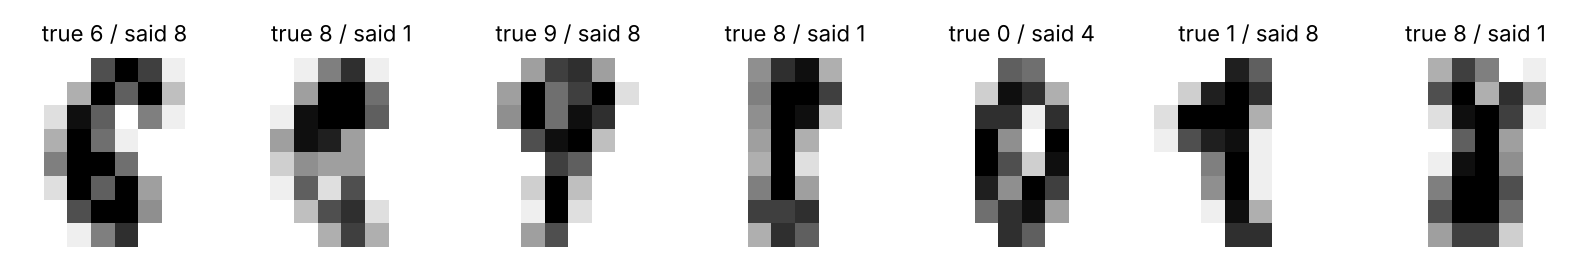

In [6]:
from sklearn.metrics import ConfusionMatrixDisplay
pred = net.predict(X_test)
ConfusionMatrixDisplay.from_predictions(y_test, pred); plt.show()

wrong = np.where(pred != y_test)[0][:8]
fig, axes = plt.subplots(1, len(wrong), figsize=(10,2))
for ax, i in zip(np.atleast_1d(axes), wrong):
    ax.imshow(X_test[i].reshape(8,8), cmap="gray_r"); ax.set_title(f"true {y_test[i]} / said {pred[i]}", fontsize=8); ax.axis("off")
plt.show()

## Step 7. Experiment with the network's size

In [7]:
for layers in [(8,), (32,), (64,), (128, 64)]:
    m = MLPClassifier(hidden_layer_sizes=layers, max_iter=1000, random_state=42).fit(X_train, y_train)
    print(f"hidden layers {str(layers):10s} accuracy {accuracy_score(y_test, m.predict(X_test)):.3f}")

hidden layers (8,)       accuracy 0.958


hidden layers (32,)      accuracy 0.978


hidden layers (64,)      accuracy 0.981


hidden layers (128, 64)  accuracy 0.981


## Step 8. Draw your own digit and test it
Change the 0s and 1s to draw a digit (8 × 8).

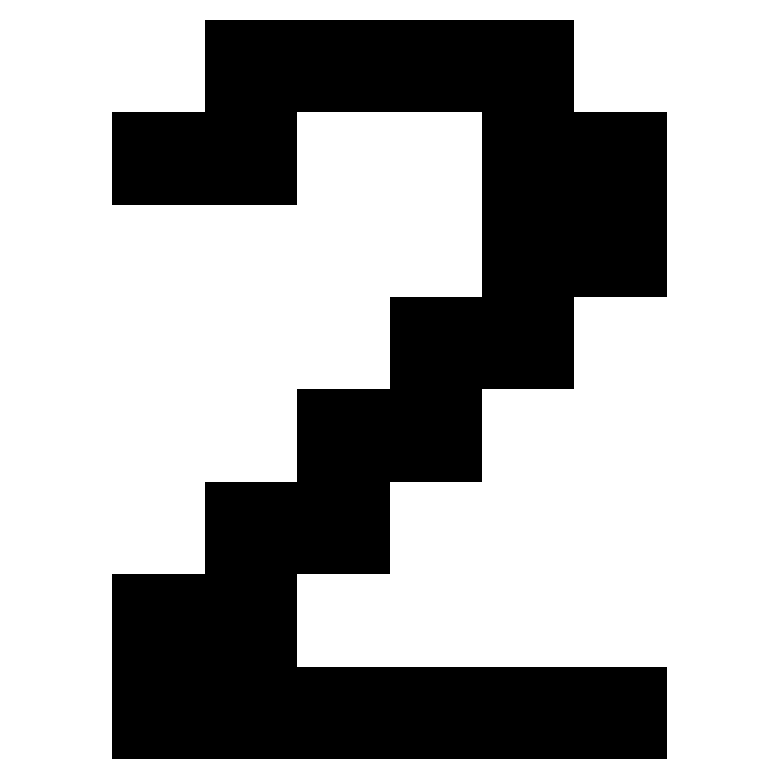

The network thinks this is: 2  (confidence 1.0 )


In [8]:
my_digit = np.array([
    [0,0,1,1,1,1,0,0],
    [0,1,1,0,0,1,1,0],
    [0,0,0,0,0,1,1,0],
    [0,0,0,0,1,1,0,0],
    [0,0,0,1,1,0,0,0],
    [0,0,1,1,0,0,0,0],
    [0,1,1,0,0,0,0,0],
    [0,1,1,1,1,1,1,0],
], dtype=float)
plt.imshow(my_digit, cmap="gray_r"); plt.axis("off"); plt.show()
probs = net.predict_proba(my_digit.reshape(1, -1))[0]
print("The network thinks this is:", probs.argmax(), " (confidence", round(probs.max(), 2), ")")

## Optional Step 9. A deeper network with Keras on MNIST (70,000 images)
This uses TensorFlow, which is already installed in Colab. It takes about 1 to 2 minutes.

In [9]:
RUN_KERAS = False   # change to True in Colab to run this step

if RUN_KERAS:
    import tensorflow as tf
    (xtr, ytr), (xte, yte) = tf.keras.datasets.mnist.load_data()
    xtr, xte = xtr / 255.0, xte / 255.0
    model = tf.keras.Sequential([
        tf.keras.layers.Flatten(input_shape=(28, 28)),
        tf.keras.layers.Dense(128, activation="relu"),
        tf.keras.layers.Dense(10, activation="softmax"),
    ])
    model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    model.fit(xtr, ytr, epochs=3, validation_split=0.1)
    print("Test accuracy:", model.evaluate(xte, yte, verbose=0)[1])

## Your turn: extensions
1. Draw a 7 and a 1. Does the network tell them apart?
2. Watch a network learn in your browser at playground.tensorflow.org.
3. Discuss: a digit reader is used to sort post. What happens when it is wrong, and who should check?

---
*Intelligent Futures · Dr. Janet Bih Shufor · Free for classroom use with attribution.*